# Model Training & Evaluation

**Project:** Bank Marketing Campaign Analysis  
**Objective:** Build and compare classification models to predict customer subscription

---

## 1. Setup

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import  RobustScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, confusion_matrix, roc_curve, auc
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import xgboost as xgb

# Imbalanced-learn
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 2. Load Preprocessed Data

In [2]:
# Load data
df = pd.read_csv('../data/processed/train_preprocessed.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nTarget distribution:")
print(df['subscribed'].value_counts())
print(f"\nClass balance:")
print(df['subscribed'].value_counts(normalize=True) * 100)

Dataset shape: (22605, 31)

Target distribution:
subscribed
0    19918
1     2687
Name: count, dtype: int64

Class balance:
subscribed
0    88.113249
1    11.886751
Name: proportion, dtype: float64


## 3. Data Preparation

We'll prepare our data by:
1. Splitting into features (X) and target (y)
2. Creating train and test sets
3. Handling class imbalance using SMOTE
4. Scaling the features

In [3]:
# Split features and target
X = df.drop(columns=['subscribed'])
y = df['subscribed']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (20344, 30)
Testing set shape: (2261, 30)


In [4]:
# Handle class imbalance with SMOTE
smote = SMOTE(random_state=42,k_neighbors=5)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# Scale features
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

print("Balanced training set shape:", X_train_scaled.shape)
print("Original class distribution:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Balanced class distribution:", dict(zip(*np.unique(y_train_balanced, return_counts=True))))

Balanced training set shape: (35852, 30)
Original class distribution: {0: 17926, 1: 2418}
Balanced class distribution: {0: 17926, 1: 17926}


## 4. Model Training and Evaluation

We'll train multiple models and compare their performance:
1. Logistic Regression (baseline)
2. Random Forest
3. XGBoost
4. LightGBM

In [5]:
# Function to evaluate model performance
def evaluate_model(model, X_train, X_test, y_train, y_test):
    # Train the model
    model.fit(X_train, y_train)
    
    # Make predictions
    y_pred = model.predict(X_test)
    
    # Calculate metrics
    results = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'auc_roc': roc_auc_score(y_test, y_pred)
    }
    
    return results

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),    
    'XGBoost': xgb.XGBClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB()
    }

# Train and evaluate each model
results = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    results[name] = evaluate_model(
        model, X_train_scaled, X_test_scaled, y_train_balanced, y_test
    )
    
# Create results DataFrame
results_df = pd.DataFrame(results).round(4)
print("\nModel Comparison:")
display(results_df)


Training Logistic Regression...

Training Random Forest...

Training XGBoost...

Training Gradient Boosting...

Training AdaBoost...

Training Decision Tree...

Training KNN...

Training Naive Bayes...

Model Comparison:


,Logistic Regression,Random Forest,XGBoost,Gradient Boosting,AdaBoost,Decision Tree,KNN,Naive Bayes
accuracy,0.8377,0.8885,0.8872,0.8704,0.8669,0.8585,0.8138,0.6373
precision,0.3881,0.5282,0.5233,0.4722,0.4590,0.4282,0.3480,0.1949
recall,0.6320,0.5911,0.5836,0.7584,0.6654,0.5651,0.6468,0.6543
f1,0.4809,0.5579,0.5518,0.5820,0.5432,0.4872,0.4525,0.3003
auc_roc,0.7487,0.7599,0.7559,0.8220,0.7798,0.7316,0.7416,0.6447


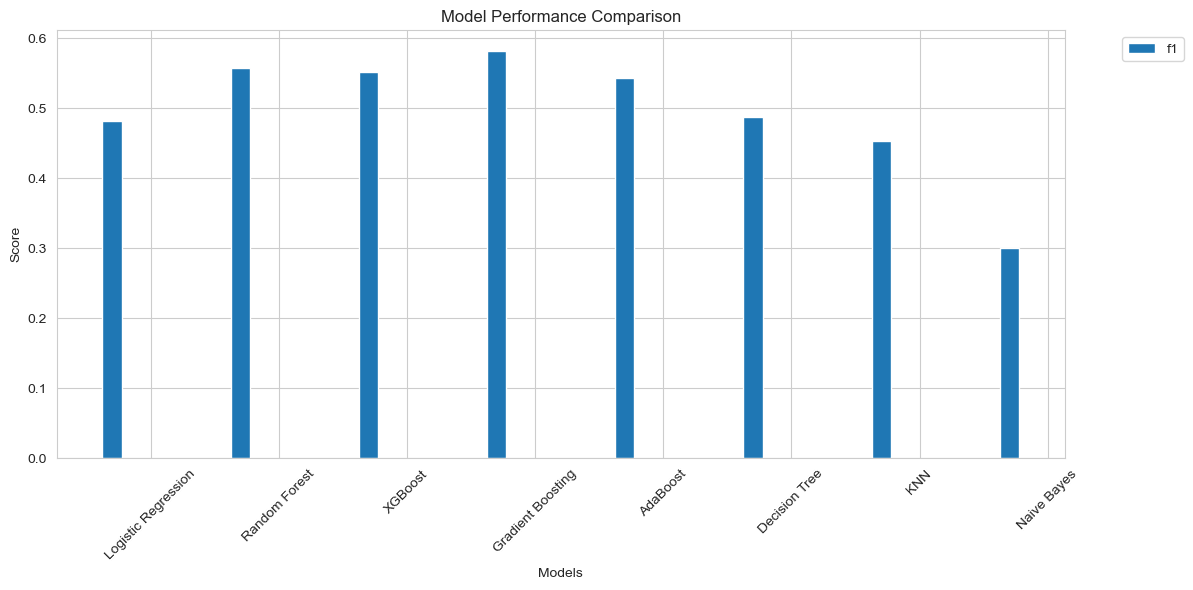

In [6]:
# Visualize results
plt.figure(figsize=(12, 6))
metrics = [ 'f1']
x = np.arange(len(models))
width = 0.15
multiplier = 0

for metric in metrics:
    offset = width * multiplier
    plt.bar(x + offset, results_df.loc[metric], width, label=metric)
    multiplier += 1

plt.xlabel('Models')
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.xticks(x + width * 2, models.keys(), rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()